# EF_mu0mlvtx: efficiency vs DV score cut, per L1 seed

Run-4 MC (μ = 200), 2000 events per sample. Per event:
- **trigger DV score** from `test_trigger/scores/<sample>/scores.csv` (HLT run without L1; empty score = no score = fail),
- **L1 TBP bits** from `test_rate/l1eff2000/<sample>/hlt/job_*/seed_table.txt` (same events, L1 emulated).

The chain passes when score > cut (nominal `MlMuonDVtxHypoTool.score_cut = 0.94`); a seeded chain also needs the L1 item.
Caveat: the Run-4 MC L1 muon emulation fires on many fake triggers (e.g. L1_MU14FCH in ~26% of dijet events), so seeded efficiencies are optimistic.

The last section shows the EB-data rate (run 500306, 2e34) vs the cut, once `dv_seed_scan.py --outDir rates_eb500306_score` has run.

In [1]:
import csv, glob, os
import numpy as np
import matplotlib.pyplot as plt

DV_DIR = "/eos/project-f/fcc-ml/ddicroce/ATLAS_MuonSpectrometer/KubeFlow/Inference_DisplacedVtx"
SCORES_DIR = f"{DV_DIR}/test_trigger/scores"
L1_DIR = f"{DV_DIR}/test_rate/l1eff2000"

# sample dir -> (label, is_signal); colours follow this order (fixed, not by rank)
SAMPLES = {
    "Haa4mu_m8_ctau500_mu200":    (r"H$\to$aa$\to$4$\mu$, $m_a$=8 GeV, c$\tau$=500 mm", True),
    "a_mumu_m2_ctau100_mu200":    (r"a$\to\mu\mu$, $m_a$=2 GeV, c$\tau$=100 mm", True),
    "a_mumu_m8_ctau500_mu200":    (r"a$\to\mu\mu$, $m_a$=8 GeV, c$\tau$=500 mm", True),
    "a_mumu_m100_ctau5000_mu200": (r"a$\to\mu\mu$, $m_a$=100 GeV, c$\tau$=5000 mm", True),
    "Zmumu_mu200":                (r"Z$\to\mu\mu$", False),
    "ttbar_mu200":                (r"$t\bar{t}$", False),
    "JPSI_mu200":                 (r"J/$\psi\to\mu\mu$", False),
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]

SEEDS = [None, "L1_MU14FCH", "L1_2MU3V"]      # None = no L1 requirement
NOMINAL_CUT = 0.94
CUTS = np.linspace(0.5, 0.995, 100)

In [2]:
L1_ITEMS = None

def load(sample):
    """per-event trigger score (-1 = none) and L1 bits {item: bool array}, matched by event number"""
    global L1_ITEMS
    with open(f"{SCORES_DIR}/{sample}/scores.csv") as fh:
        score = {int(r["event"]): float(r["trg_score"]) if r["trg_score"] not in ("", "nan") else -1.0
                 for r in csv.DictReader(fh)}
    events, bits = [], []
    for path in sorted(glob.glob(f"{L1_DIR}/{sample}/hlt/job_*/seed_table.txt")):
        with open(path) as fh:
            for line in fh:
                if line.startswith("#"):
                    L1_ITEMS = line[1:].split()[4:]
                    continue
                f = line.split()
                events.append(int(f[0]))
                bits.append([int(b) for b in f[4:]])
    bits = np.array(bits, dtype=bool)
    s = np.array([score.get(e, -1.0) for e in events])
    missing = sum(e not in score for e in events)
    if missing:
        print(f"{sample}: {missing} events without a trigger score (counted as fail)")
    return s, {it: bits[:, k] for k, it in enumerate(L1_ITEMS)}

data = {s: load(s) for s in SAMPLES}
for s, (sc, l1) in data.items():
    print(f"{s:28s} {len(sc):5d} events, eff(no L1, >{NOMINAL_CUT}) = {np.mean(sc > NOMINAL_CUT):.3f}")

Haa4mu_m8_ctau500_mu200       2000 events, eff(no L1, >0.94) = 0.913
a_mumu_m2_ctau100_mu200       2000 events, eff(no L1, >0.94) = 0.591
a_mumu_m8_ctau500_mu200       2000 events, eff(no L1, >0.94) = 0.699
a_mumu_m100_ctau5000_mu200    2000 events, eff(no L1, >0.94) = 0.459
Zmumu_mu200                   2000 events, eff(no L1, >0.94) = 0.013
ttbar_mu200                   2000 events, eff(no L1, >0.94) = 0.011
JPSI_mu200                    2000 events, eff(no L1, >0.94) = 0.006


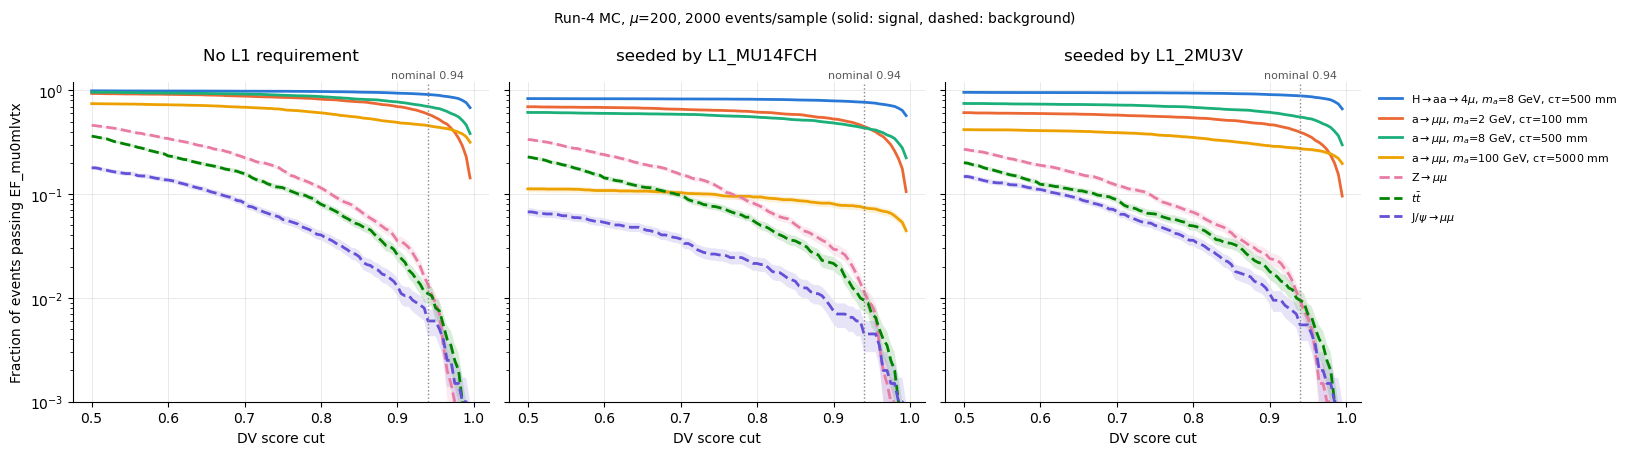

In [3]:
def efficiency(sample, seed, cuts):
    sc, l1 = data[sample]
    sel = sc if seed is None else np.where(l1[seed], sc, -1.0)
    n = len(sc)
    eff = np.array([np.count_nonzero(sel > c) / n for c in cuts])
    return eff, np.sqrt(eff * (1 - eff) / n)

fig, axes = plt.subplots(1, len(SEEDS), figsize=(4.6 * len(SEEDS) + 2.6, 4.6), sharey=True)
for ax, seed in zip(axes, SEEDS):
    for (sample, (label, is_sig)), color in zip(SAMPLES.items(), COLORS):
        eff, err = efficiency(sample, seed, CUTS)
        ok = eff > 0  # log scale: drop empty points
        ax.plot(CUTS[ok], eff[ok], color=color, lw=2, ls="-" if is_sig else "--", label=label)
        ax.fill_between(CUTS[ok], (eff - err)[ok], (eff + err)[ok], color=color, alpha=0.15, lw=0)
    ax.axvline(NOMINAL_CUT, color="#888888", lw=1, ls=":")
    ax.text(NOMINAL_CUT, 1.25, f"nominal {NOMINAL_CUT}", color="#555555", fontsize=8, ha="center", va="bottom")
    ax.set_title("No L1 requirement" if seed is None else f"seeded by {seed}", pad=16)
    ax.set_xlabel("DV score cut")
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1.2)
    ax.grid(True, which="major", color="#e5e5e5", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Fraction of events passing EF_mu0mlvtx")
axes[-1].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle(r"Run-4 MC, $\mu$=200, 2000 events/sample (solid: signal, dashed: background)", fontsize=10)
fig.tight_layout()
plt.show()

In [4]:
# Same numbers as a table at a few cuts
TABLE_CUTS = [0.5, 0.8, 0.9, 0.92, 0.94, 0.96, 0.98, 0.99]
print(f"{'sample':28s} {'seed':11s} " + " ".join(f"{c:>6.2f}" for c in TABLE_CUTS))
for sample in SAMPLES:
    for seed in SEEDS:
        eff, _ = efficiency(sample, seed, TABLE_CUTS)
        print(f"{sample:28s} {seed or 'no L1':11s} " + " ".join(f"{100 * e:6.1f}" for e in eff))

sample                       seed          0.50   0.80   0.90   0.92   0.94   0.96   0.98   0.99
Haa4mu_m8_ctau500_mu200      no L1         99.2   97.5   94.1   93.1   91.3   88.1   83.5   76.2
Haa4mu_m8_ctau500_mu200      L1_MU14FCH    83.5   82.1   79.3   78.4   77.0   74.2   70.1   64.2
Haa4mu_m8_ctau500_mu200      L1_2MU3V      95.9   94.2   91.1   90.2   88.6   85.7   81.2   74.1
a_mumu_m2_ctau100_mu200      no L1         93.5   82.4   69.8   65.6   59.1   49.4   34.6   22.9
a_mumu_m2_ctau100_mu200      L1_MU14FCH    69.7   61.8   53.0   50.0   44.9   37.6   26.1   17.6
a_mumu_m2_ctau100_mu200      L1_2MU3V      61.1   54.5   46.8   44.0   39.6   33.0   23.6   15.5
a_mumu_m8_ctau500_mu200      no L1         96.2   87.2   77.5   73.8   69.9   64.7   55.6   46.5
a_mumu_m8_ctau500_mu200      L1_MU14FCH    61.4   55.4   48.6   46.2   43.5   40.2   34.4   28.0
a_mumu_m8_ctau500_mu200      L1_2MU3V      74.9   68.8   61.7   58.6   55.4   51.5   44.0   36.6
a_mumu_m100_ctau5000_mu200   n

## EB data rate vs score cut (run 500306, 2e34)

Needs `rates_eb500306_score/ratesAnalysis/log.txt` (`run_dv_rates.sh --rates-only`) and the per-job cache
`rates_eb500306_score/seedScan/` (`dv_seed_scan.py --outDir rates_eb500306_score`). Weights as in `dv_seed_scan.py`:
EB weight × L_target / L_LB, normalised to the RatesAnalysis L1_MU3V rate.

1029078 EB events from 597 files, L1_MU3V = 2.15 MHz
L1_MU3V      rate at score > 0.94:   5215.6 Hz
L1_MU14FCH   rate at score > 0.94:    176.4 Hz
L1_2MU3V     rate at score > 0.94:    375.6 Hz


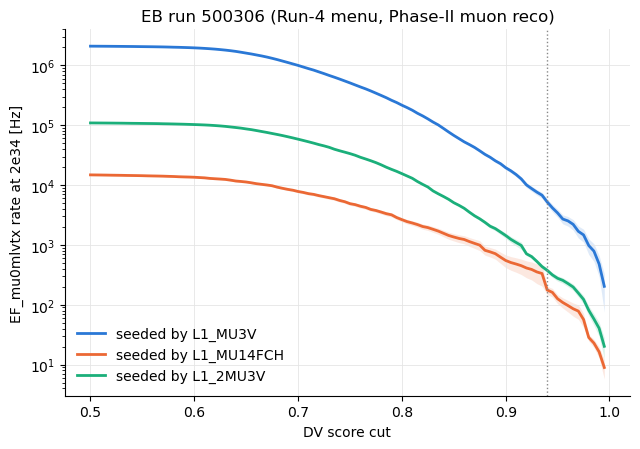

In [5]:
import sys
sys.path.insert(0, f"{DV_DIR}/test_rate")
from dv_seed_scan import eb_weights, ref_rate

EB_OUT = f"{DV_DIR}/test_rate/rates_eb500306_score"
RUN, TARGET_L = 500306, 2e34
rates_log = f"{EB_OUT}/ratesAnalysis/log.txt"
tables = sorted(glob.glob(f"{EB_OUT}/seedScan/*.txt"))
if not (os.path.exists(rates_log) and tables):
    print("EB rate inputs not there yet: run the rates step and dv_seed_scan.py first")
else:
    weights, lumi = eb_weights(RUN)
    w, sc, bits = [], [], []
    for path in tables:
        with open(path) as fh:
            for line in fh:
                if line.startswith("#"):
                    items = line[1:].split()[4:]
                    continue
                f = line.split()
                ev, lb = int(f[0]), int(f[1])
                if ev not in weights or lb not in lumi:
                    continue
                w.append(weights[ev] * TARGET_L / (lumi[lb] * 1e30))
                sc.append(float(f[3]))
                bits.append([int(b) for b in f[4:]])
    w, sc, bits = np.array(w), np.array(sc), np.array(bits, dtype=bool)
    l1 = {it: bits[:, k] for k, it in enumerate(items)}
    scale = ref_rate(rates_log, "L1_MU3V") / w[l1["L1_MU3V"]].sum()  # Hz per unit weight
    print(f"{len(w)} EB events from {len(tables)} files, L1_MU3V = {ref_rate(rates_log, 'L1_MU3V') / 1e6:.2f} MHz")

    # The chain is seeded by L1_MU3V in data, so 'no L1' is not available: MU3V is the loosest seed
    EB_SEEDS = ["L1_MU3V", "L1_MU14FCH", "L1_2MU3V"]
    fig, ax = plt.subplots(figsize=(6.5, 4.6))
    for seed, color in zip(EB_SEEDS, ["#2a78d6", "#eb6834", "#1baf7a"]):
        m = l1[seed] & l1["L1_MU3V"]
        rate = np.array([w[m & (sc > c)].sum() for c in CUTS]) * scale
        err = np.array([np.sqrt((w[m & (sc > c)] ** 2).sum()) for c in CUTS]) * scale
        ok = rate > 0
        ax.plot(CUTS[ok], rate[ok], color=color, lw=2, label=f"seeded by {seed}")
        ax.fill_between(CUTS[ok], (rate - err)[ok].clip(min=1e-3), (rate + err)[ok], color=color, alpha=0.15, lw=0)
        i = np.argmin(abs(CUTS - NOMINAL_CUT))
        print(f"{seed:12s} rate at score > {NOMINAL_CUT}: {w[m & (sc > NOMINAL_CUT)].sum() * scale:8.1f} Hz")
    ax.axvline(NOMINAL_CUT, color="#888888", lw=1, ls=":")
    ax.set_yscale("log")
    ax.set_xlabel("DV score cut")
    ax.set_ylabel("EF_mu0mlvtx rate at 2e34 [Hz]")
    ax.set_title("EB run 500306 (Run-4 menu, Phase-II muon reco)")
    ax.grid(True, which="major", color="#e5e5e5", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

## Summary tables (as sent to the trigger experts)

Chain decision = `HLTPassRaw` of EF_mu0mlvtx_L1MU3V (score > 0.94), seed = chain AND L1 TBP bit.
Needs only the first code cell (paths) to have run.

In [6]:
import re
import pandas as pd
import sys
sys.path.insert(0, f"{DV_DIR}/test_rate")
from dv_seed_scan import eb_weights, ref_rate

def read_tables(paths):
    """seed_table / seedScan files -> DataFrame (event lb chain score + one bool column per L1 item)"""
    frames = []
    for path in paths:
        with open(path) as fh:
            cols = fh.readline()[1:].split()
        frames.append(pd.read_csv(path, sep=r"\s+", comment="#", names=cols))
    df = pd.concat(frames, ignore_index=True)
    for c in df.columns[4:]:
        df[c] = df[c].astype(bool)
    df["chain"] = df["chain"].astype(bool)
    return df

def label(sample):
    """directory name -> physics label"""
    m = re.match(r"(Haa4mu|a_mumu)_m(\d+)_ctau(\d+)_mu200", sample)
    if m:
        proc = "H→aa→4μ" if m.group(1) == "Haa4mu" else "a→μμ"
        return f"{proc}, m_a = {m.group(2)} GeV, cτ = {m.group(3)} mm"
    return {"JPSI_mu200": "J/ψ→μμ", "Zmumu_mu200": "Z→μμ", "ttbar_mu200": "tt̄", "jj_mu200": "dijets (jj)"}.get(sample, sample)

BACKGROUNDS = ["JPSI_mu200", "Zmumu_mu200", "ttbar_mu200", "jj_mu200"]
def sort_key(s):
    m = re.match(r"(Haa4mu|a_mumu)_m(\d+)_ctau", s)
    return (0, m.group(1) != "Haa4mu", int(m.group(2))) if m else (1, BACKGROUNDS.index(s), 0)

mc = {s: read_tables(sorted(glob.glob(f"{L1_DIR}/{s}/hlt/job_*/seed_table.txt")))
      for s in sorted((d for d in os.listdir(L1_DIR) if os.path.isdir(f"{L1_DIR}/{d}")), key=sort_key)}
print({s: len(df) for s, df in mc.items()})

{'Haa4mu_m4_ctau200_mu200': 2000, 'Haa4mu_m6_ctau200_mu200': 2000, 'Haa4mu_m8_ctau500_mu200': 2000, 'Haa4mu_m10_ctau500_mu200': 2000, 'a_mumu_m2_ctau100_mu200': 2000, 'a_mumu_m4_ctau100_mu200': 2000, 'a_mumu_m6_ctau100_mu200': 2000, 'a_mumu_m8_ctau500_mu200': 2000, 'a_mumu_m10_ctau500_mu200': 2000, 'a_mumu_m20_ctau500_mu200': 2000, 'a_mumu_m50_ctau1000_mu200': 2000, 'a_mumu_m100_ctau5000_mu200': 2000, 'JPSI_mu200': 2000, 'Zmumu_mu200': 2000, 'ttbar_mu200': 2000, 'jj_mu200': 2000}


### 1) Rate per L1 seed (EB run 500306, 2e34)
The DV step runs on the full event, not on L1 RoIs, so the rate for any seed comes from the events where both the chain and that L1 item fire.

In [7]:
EB_OUT = f"{DV_DIR}/test_rate/rates_eb500306_score"
RUN, TARGET_L = 500306, 2e34
eb = read_tables(sorted(glob.glob(f"{EB_OUT}/seedScan/*.txt")))
weights, lumi = eb_weights(RUN)
eb = eb[eb["event"].isin(weights.keys()) & eb["lb"].isin(lumi.keys())]
eb["w"] = eb["event"].map(weights) * TARGET_L / (eb["lb"].map(lumi) * 1e30)
rates_log = f"{EB_OUT}/ratesAnalysis/log.txt"
scale = ref_rate(rates_log, "L1_MU3V") / eb.loc[eb["L1_MU3V"], "w"].sum()  # Hz per unit weight

def fmt_rate(r):
    return f"{r / 1e6:.2f} MHz" if r >= 1e6 else f"{r / 1e3:.3g} kHz" if r >= 1e3 else f"{r:.0f} Hz"

rows = []
for item in [c for c in eb.columns[4:] if c.startswith("L1_")]:
    sel = eb[eb[item] & eb["L1_MU3V"] & eb["chain"]]
    rows.append({"L1 seed": item + (" (current)" if item == "L1_MU3V" else ""),
                 "L1 rate": fmt_rate(eb.loc[eb[item], "w"].sum() * scale),
                 "EF_mu0mlvtx rate": f"{fmt_rate(sel['w'].sum() * scale)} ± {fmt_rate((sel['w'] ** 2).sum() ** 0.5 * scale)}",
                 "EB events passing": len(sel)})
print(f"{len(eb)} EB events, {eb['event'].nunique()} unique")
pd.DataFrame(rows).set_index("L1 seed")

1029078 EB events, 1029078 unique


,L1 rate,EF_mu0mlvtx rate,EB events passing
L1 seed,,,
L1_MU3V (current),2.15 MHz,5.22 kHz ± 654 Hz,1420
L1_MU5VF,495 kHz,2.09 kHz ± 330 Hz,1250
L1_MU8F,242 kHz,1.03 kHz ± 106 Hz,1129
L1_MU8VF,72.1 kHz,355 Hz ± 49 Hz,951
L1_MU14FCH,16.4 kHz,176 Hz ± 27 Hz,681
L1_MU18VFCH,13.8 kHz,155 Hz ± 22 Hz,647
L1_2MU3V,113 kHz,376 Hz ± 33 Hz,493


### 2) Efficiency per seed (Run-4 MC, μ = 200)
Fraction of events that pass the chain. "No L1" is the HLT alone, and the other columns also require the L1 item.
2000 events per sample, so the statistical error is ≤ 1% (signal) and ≤ 0.3% (background).
L1_MU3V gives the same numbers as No L1 (every event that passes the chain also fires it), so it is not shown.

In [8]:
EFF_SEEDS = ["L1_MU8F", "L1_MU14FCH", "L1_2MU3V"]
rows = {}
for s, df in mc.items():
    assert not (df["chain"] & ~df["L1_MU3V"]).any(), f"{s}: chain passes without L1_MU3V"
    row = {"N": len(df), "No L1": 100 * df["chain"].mean()}
    row.update({seed.replace("L1_", ""): 100 * (df["chain"] & df[seed]).mean() for seed in EFF_SEEDS})
    rows[label(s)] = row
eff = pd.DataFrame(rows).T
eff["N"] = eff["N"].astype(int)
eff.style.format({c: "{:.1f}%" for c in eff.columns if c != "N"})

,N,No L1,MU8F,MU14FCH,2MU3V
"H→aa→4μ, m_a = 4 GeV, cτ = 200 mm",2000,86.2%,85.5%,79.3%,83.7%
"H→aa→4μ, m_a = 6 GeV, cτ = 200 mm",2000,88.0%,87.2%,80.3%,85.8%
"H→aa→4μ, m_a = 8 GeV, cτ = 500 mm",2000,91.3%,89.3%,77.0%,88.6%
"H→aa→4μ, m_a = 10 GeV, cτ = 500 mm",2000,91.3%,88.6%,73.5%,88.2%
"a→μμ, m_a = 2 GeV, cτ = 100 mm",2000,59.1%,54.0%,44.9%,39.6%
"a→μμ, m_a = 4 GeV, cτ = 100 mm",2000,61.3%,57.2%,47.3%,45.4%
"a→μμ, m_a = 6 GeV, cτ = 100 mm",2000,61.8%,58.6%,49.7%,50.6%
"a→μμ, m_a = 8 GeV, cτ = 500 mm",2000,69.9%,62.0%,43.5%,55.4%
"a→μμ, m_a = 10 GeV, cτ = 500 mm",2000,70.9%,61.9%,44.8%,56.9%
"a→μμ, m_a = 20 GeV, cτ = 500 mm",2000,61.0%,50.3%,33.9%,47.7%


### 3) L1 firing rate on background MC (no ML filter)
Fraction of background events in which each L1 item fires (TBP), independent of the HLT chain.
For comparison, in Run-3 data L1_MU14FCH accepts well under 1% of crossings, so these show the fake-dominated L1 emulation.

In [9]:
L1_SHOW = ["L1_MU3V", "L1_MU8F", "L1_MU14FCH", "L1_2MU3V"]
fire = pd.DataFrame({label(s): {it.replace("L1_", ""): 100 * mc[s][it].mean() for it in L1_SHOW}
                     for s in BACKGROUNDS if s in mc}).T
fire.style.format("{:.1f}%")

,MU3V,MU8F,MU14FCH,2MU3V
J/ψ→μμ,99.2%,80.8%,19.9%,84.9%
Z→μμ,88.6%,77.6%,69.9%,59.0%
tt̄,78.5%,57.4%,45.6%,44.8%
dijets (jj),85.9%,58.0%,25.6%,62.8%
